# Rate Experiment — corrected herald accounting

Reports the **honest live-atom herald probability** (reused heralds, `how_many_atoms==0`) next to the naive aggregate, which is biased low by turnover-contaminated first-after-load windows. Thin driver over `analyze_rate_corrected.py`.

> Run in the working-BLAS `python` env, NOT `artiq7_claude`.

## 0. Setup

In [343]:
%load_ext autoreload
%autoreload 2
import sys, os
from pathlib import Path
ANALYSIS_DIR = Path(r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\analysis")
for p in (str(ANALYSIS_DIR.parent), str(ANALYSIS_DIR)):
    if p not in sys.path: sys.path.insert(0, p)
from analyze_rate_corrected import find_runs, load_run, herald_stats, print_summary, plot_herald, RESULTS_DIR
%matplotlib inline
print("Setup complete"); print("Results dir:", RESULTS_DIR)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Setup complete
Results dir: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results


## 1. List runs

In [344]:
for fp in find_runs():
    print(os.path.basename(fp))

000000660-RateExperiment.h5
000000661-RateExperiment.h5
000000664-RateExperiment.h5
000000667-RateExperiment.h5
000000671-RateExperiment.h5
000000674-RateExperiment.h5
000000677-RateExperiment.h5
000000714-RateExperiment.h5
000000717-RateExperiment.h5
000003496-RateExperiment.h5
000003513-RateExperiment.h5
000003522-RateExperiment.h5
000003611-RateExperiment.h5
000003614-RateExperiment.h5
000003617-RateExperiment.h5
000003620-RateExperiment.h5
000003623-RateExperiment.h5
000003626-RateExperiment.h5
000003629-RateExperiment.h5
000003632-RateExperiment.h5
000003635-RateExperiment.h5
000003638-RateExperiment.h5
000003643-RateExperiment.h5


## 2. Load & summarize (naive vs honest herald p)

In [345]:
########################################
RID = None    # int RID, or None for latest
########################################
files = find_runs()
if RID is not None:
    path = [f for f in files if os.path.basename(f).split('-')[0] == f"{RID:09d}"][-1]
else:
    path = files[-1]; print("(latest run)")
d = load_run(path)
s = herald_stats(d)
print_summary(s)

(latest run)
File: 000003643-RateExperiment.h5   RID=3643   duration=779.3 s
  clicks=1000   attempts=255956   loads=1042   clicks/load=0.96
  clicks/s=1.283   attempts/s=328

  herald p  (NAIVE, clicks/attempts)       = 0.391 %   <- biased LOW
  herald p  (LIVE atom, reused heralds)    = 0.793 %   <- honest per-attempt
  herald p  (FRESH, first-after-load)      = 0.236 %   (turnover-inflated: 424 vs 126 attempts)
  turnover overhead ~ 298 extra attempts per reload (436 reloads-with-herald of 1000 clicks)

  per-herald-position on the same atom (flat beyond #1 => recool is fine):
    herald #      N  mean attempts      p %
           1    436          423.9    0.236
           2    247          130.1    0.768
           3    134          112.2    0.892
           4     84          142.8    0.700
           5     48          117.4    0.852
           6     27          112.1    0.892
           7     12          142.5    0.702
           8      7          191.0    0.524


## 3. Diagnostics plot (per-position attempts + live vs turnover windows)

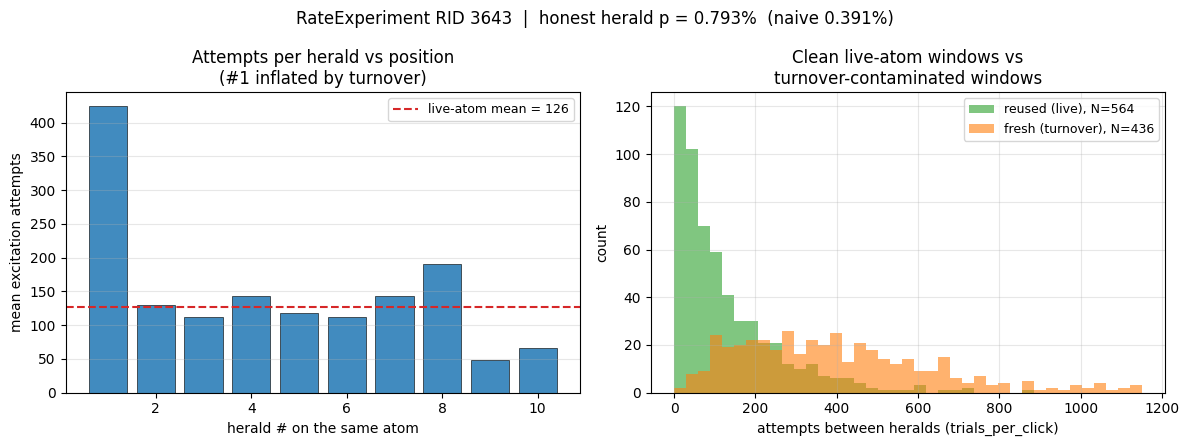

In [346]:
plot_herald(s, d)